# NB07 — Rolling-horizon operation with forecasts (2023)

**SOLA4237 Assignment 2 — single-site battery optimisation, Toowoomba (QLD)**

**Purpose.** Notebook 6 gave the cost-optimised battery perfect knowledge of PV and prices (run R1 = upper bound). Here the **plan** is made with
forecasts, exactly as a real controller would: every hour a 48 h plan from the information available at that moment, executed for one hour at
5-min resolution with the actual PV, load and SoC, and settled at actual prices. Measure how much of the R1 value survives.

| Run | PV in the plan | Prices in the plan | Tariffs |
|---|---|---|---|
| R1 | actual (perfect) | actual (perfect) | all — from Notebook 6 (S3) |
| R2 | Notebook 3 forecast (M2 decision tree) | actual / known tariff | all |
| R3 | actual | AEMO pre-dispatch, extended to 48 h (Notebook 4) | wholesale |
| R4 | Notebook 3 forecast | AEMO pre-dispatch | wholesale |

Flat and ToU prices are known in advance, so for them R3 = R1 and R4 = R2. **Comparison runs** (cheap baselines, Topic 4 slide 33):
- **R2n** — PV plan = actual PV at the same hour on the latest observed day ("seasonal naive"). Notebook 3's forecast uses *measured* 2023 weather,
  so R2 has almost no forecast error; R2n shows the effect of a poor PV forecast.
- **R3n** — price plan = actual price at the same hour on the latest observed day (Notebook 4: naive has lower MAE than pre-dispatch overall).
- **R3cap** — pre-dispatch capped at $300/MWh in the plan (Notebook 4: pre-dispatch forecasts ~5× more spikes than occur; precision 18 %).

**Metric:** value retained = (S1 cost − run cost) ÷ (S1 cost − R1 cost), using energy cost without the VPP fee (the fee is the same for every
wholesale run). The load in every plan is the actual hourly load (the 2023 load repeats 2022, so no independent load forecast is possible —
a stated limitation).

**Inputs:** `outputs/nb01_clean_2022_2023.csv`, `outputs/nb03_pv_forecast_2023_hourly.csv`, `outputs/nb04_pd_forecast_wide_2023.csv`,
`outputs/nb06_results_2023.csv`, `outputs/nb06_dispatch_*_S1/S3.csv.gz`, `bess_functions.py`.
**Outputs:** `outputs/nb07_results_2023.csv`, `outputs/nb07_dispatch_<tariff>_<run>.csv.gz`, figures fig10a–fig10c.
**Run order:** after NB01, NB03, NB04, NB06. Runtime ≈ 10 runs × 1 min ≈ 10–15 minutes in Colab.

## Cell 0 — Settings

In [1]:
# Cell 0 - Settings: runs in Google Colab and in local Jupyter
import sys, os
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_DIR = '/content/drive/MyDrive/SOLA4237-A2'
else:
    BASE_DIR = os.getcwd()                    # local: the data folder or its 'Notebook' subfolder
    if not os.path.exists(os.path.join(BASE_DIR, 'QLD_spot_price_2023')):
        BASE_DIR = os.path.dirname(BASE_DIR)
sys.path.append(BASE_DIR)
OUT_DIR = os.path.join(BASE_DIR, 'outputs')
FIG_DIR = os.path.join(OUT_DIR, 'figures')
os.makedirs(FIG_DIR, exist_ok=True)
assert os.path.exists(os.path.join(BASE_DIR, 'bess_functions.py')), 'Upload bess_functions.py to ' + BASE_DIR
print('BASE_DIR:', BASE_DIR)

Mounted at /content/drive
BASE_DIR: /content/drive/MyDrive/SOLA4237-A2


## Cell 1 — Imports, 2023 data and NB06 reference results

In [2]:
# Cell 1 - imports and data
import time, importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import bess_functions as bf
importlib.reload(bf)

DT_H = 5 / 60
H = 48                                         # planning horizon (hours)
VPP_FEE_AUD = 300.0
TARIFFS = {'flat': ('import_flat_aud_kwh', 'export_flat_aud_kwh'),
           'tou': ('import_tou_aud_kwh', 'export_tou_aud_kwh'),
           'wholesale': ('import_wholesale_aud_kwh', 'export_wholesale_aud_kwh')}
COL = {'R1': '#1f4e79', 'R2': '#55a868', 'R2n': '#a6d49f', 'R3': '#c44e52', 'R3cap': '#dd8452', 'R3n': '#e9a3a5', 'R4': '#8172b3',
       'price': '#7f7f7f'}
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 20)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3, 'axes.spines.top': False, 'axes.spines.right': False})

df = pd.read_csv(os.path.join(OUT_DIR, 'nb01_clean_2022_2023.csv'), parse_dates=['datetime']).set_index('datetime')
y23 = df.loc['2023-01-01 00:05':'2023-12-31 23:55']
nb06 = pd.read_csv(os.path.join(OUT_DIR, 'nb06_results_2023.csv')).set_index(['tariff', 'scenario'])
runs = {}
for tname in TARIFFS:                          # reuse NB06 runs: S1 (PV only) and S3 (= R1, perfect foresight)
    for sc, name in [('S1', 'S1'), ('S3', 'R1')]:
        runs[(tname, name)] = pd.read_csv(os.path.join(OUT_DIR, f'nb06_dispatch_{tname}_{sc}.csv.gz'),
                                          parse_dates=['datetime'], index_col='datetime')
print('2023 intervals:', len(y23), '| NB06 R1 bills:', nb06.xs('S3', level='scenario')['bill_aud'].round(0).to_dict())

2023 intervals: 105119 | NB06 R1 bills: {'flat': 107.0, 'tou': -70.0, 'wholesale': -159.0}


## Cell 2 — Forecast inputs as functions of the plan time t
`run_operation` asks, at each plan time t (hh:00), for 48 hourly values: the hours ending t+1 h … t+48 h.
- **PV forecast (R2):** Notebook 3 hourly forecast (hour-ending labels), read through `bf.window` (repeats the last day at the end of 2023).
- **Seasonal naive (R2n, R3n):** for hours 1–24 ahead use the actual value 24 h earlier, for hours 25–48 use 48 h earlier — always the latest
  day that has already happened at time t (no look-ahead). The hourly history includes 2022, so 1–2 Jan 2023 look back into Dec 2022.
- **Pre-dispatch (R3, R4):** row t of the Notebook 4 wide table (`h01` = hour ending t+1 h). Spot forecasts are turned into tariff prices with the
  same formula as Notebook 1: import = (spot × 1.062 + network + 0.01891) × 1.10, export = spot. The network rate is a published tariff,
  so its hourly mean is known in advance and taken from the data.

In [3]:
# Cell 2 - forecast inputs
# hourly means (hour-ending labels) over 2022-2023, so the seasonal naive on 1-2 Jan 2023 can look back into Dec 2022
hourly = df[['pv_actual_kw', 'spot_aud_kwh', 'network_aud_kwh']].resample('h', label='right', closed='right').mean()

pvfc = pd.read_csv(os.path.join(OUT_DIR, 'nb03_pv_forecast_2023_hourly.csv'), parse_dates=['datetime']).set_index('datetime')['pv_forecast_kw']
pd_wide = pd.read_csv(os.path.join(OUT_DIR, 'nb04_pd_forecast_wide_2023.csv'), parse_dates=['plan_time']).set_index('plan_time')
PD_COLS = [f'h{h:02d}' for h in range(1, H + 1)]
LAG_H = np.where(np.arange(1, H + 1) <= 24, 24, 48)        # seasonal-naive lag for each step ahead

def seasonal_naive(series, t):
    # actual value at the same hour on the latest day already observed at plan time t
    targets = t + pd.to_timedelta(np.arange(1, H + 1), unit='h')
    v = series.reindex(targets - pd.to_timedelta(LAG_H, unit='h')).to_numpy(float)
    assert not np.isnan(v).any(), f'missing history at {t}'
    return v

def to_tariff(spot, t):
    # wholesale tariff prices from a spot forecast ($/kWh) for the hours ending t+1 ... t+H
    net = bf.window(hourly['network_aud_kwh'], t, H)
    return (spot * bf.LOSS_FACTOR + net + bf.ENV_MKT_AUD_KWH) * bf.GST, spot

def pv_forecast(t):
    return bf.window(pvfc, t, H)

def pv_naive(t):
    return seasonal_naive(hourly['pv_actual_kw'], t)

def price_pd(t):
    return to_tariff(pd_wide.loc[t, PD_COLS].to_numpy(float), t)

def price_pd_cap(t):
    return to_tariff(np.minimum(pd_wide.loc[t, PD_COLS].to_numpy(float), 0.300), t)

def price_naive(t):
    return to_tariff(seasonal_naive(hourly['spot_aud_kwh'], t), t)

# quick sanity check at one plan time: forecasts vs actual for the next 6 hours
t = pd.Timestamp('2023-03-15 15:00')
print(pd.DataFrame({'actual spot': bf.window(hourly['spot_aud_kwh'], t, H)[:6], 'pre-dispatch': price_pd(t)[1][:6],
                    'naive': price_naive(t)[1][:6], 'PV actual': bf.window(hourly['pv_actual_kw'], t, H)[:6],
                    'PV forecast': pv_forecast(t)[:6], 'PV naive': pv_naive(t)[:6]},
                   index=pd.date_range(t + pd.Timedelta(hours=1), periods=6, freq='h')).round(3))

                     actual spot  pre-dispatch  naive  PV actual  PV forecast  PV naive
2023-03-15 16:00:00        0.138         0.093  0.116      4.886        4.858     6.149
2023-03-15 17:00:00        0.153         0.119  0.165      3.182        3.124     4.251
2023-03-15 18:00:00        0.179         0.251  0.204      1.497        1.469     2.048
2023-03-15 19:00:00        0.246         0.541  0.331      0.322        0.326     0.483
2023-03-15 20:00:00        0.224         0.432  0.171      0.000        0.000     0.004
2023-03-15 21:00:00        0.148         0.337  0.105      0.000        0.000     0.000


## Cell 3 — Run the forecast-based strategies
Each run is a full year of hourly re-planning (8,760 LPs). Curtailment only under wholesale (decided from the *planned* export price).

In [4]:
# Cell 3 - runs
RUNS = [('flat', 'R2', pv_forecast, None), ('flat', 'R2n', pv_naive, None),
        ('tou', 'R2', pv_forecast, None), ('tou', 'R2n', pv_naive, None),
        ('wholesale', 'R2', pv_forecast, None), ('wholesale', 'R2n', pv_naive, None),
        ('wholesale', 'R3', None, price_pd), ('wholesale', 'R3cap', None, price_pd_cap),
        ('wholesale', 'R3n', None, price_naive), ('wholesale', 'R4', pv_forecast, price_pd)]
t_all = time.time()
for tname, rname, pv_fn, price_fn in RUNS:
    ic, ec = TARIFFS[tname]
    t0 = time.time()
    runs[(tname, rname)] = bf.run_operation(y23, ic, ec, mode='cost', allow_curtail=(tname == 'wholesale'),
                                            pv_plan=pv_fn, price_plan=price_fn, replan_h=1)
    print(f'{tname:9s} {rname:5s} done in {time.time() - t0:.0f} s')
print(f'total {time.time() - t_all:.0f} s')

flat      R2    done in 95 s
flat      R2n   done in 94 s
tou       R2    done in 92 s
tou       R2n   done in 93 s
wholesale R2    done in 89 s
wholesale R2n   done in 90 s
wholesale R3    done in 91 s
wholesale R3cap done in 91 s
wholesale R3n   done in 91 s
wholesale R4    done in 93 s
total 919 s


## Cell 4 — Results: bills and value retained

In [5]:
# Cell 4 - results table
ORDER = ['S1', 'R1', 'R2', 'R2n', 'R3', 'R3cap', 'R3n', 'R4']
rows = []
for (tname, rname), r in runs.items():
    fee = VPP_FEE_AUD if (tname == 'wholesale' and rname != 'S1') else 0.0
    st = bf.settle(r, fee_aud=fee)
    st.update({'tariff': tname, 'run': rname, 'vpp_fee_aud': fee})
    rows.append(st)
res = pd.DataFrame(rows)
res['run'] = pd.Categorical(res['run'], ORDER, ordered=True)
res = res.sort_values(['tariff', 'run']).reset_index(drop=True)
s1 = res[res.run == 'S1'].set_index('tariff')['energy_cost_aud']
r1 = res[res.run == 'R1'].set_index('tariff')['energy_cost_aud']
res['saving_vs_S1_aud'] = res['tariff'].map(s1) - res['energy_cost_aud']
res['value_retained'] = res['saving_vs_S1_aud'] / (res['tariff'].map(s1) - res['tariff'].map(r1))
res['loss_vs_R1_aud'] = res['energy_cost_aud'] - res['tariff'].map(r1)
res.loc[res.run == 'S1', ['value_retained']] = np.nan
show = ['tariff', 'run', 'bill_aud', 'saving_vs_S1_aud', 'value_retained', 'loss_vs_R1_aud', 'battery_export_kwh', 'curtailed_kwh',
        'equivalent_full_cycles']
print(res[show].round(3).to_string(index=False))
assert abs(res.query("tariff=='wholesale' and run=='R1'")['bill_aud'].iloc[0] - nb06.loc[('wholesale', 'S3'), 'bill_aud']) < 0.01

   tariff   run  bill_aud  saving_vs_S1_aud  value_retained  loss_vs_R1_aud  battery_export_kwh  curtailed_kwh  equivalent_full_cycles
     flat    S1   794.679             0.000             NaN         687.853               0.000          0.000                   0.000
     flat    R1   106.826           687.853           1.000           0.000               0.000          0.000                 208.372
     flat    R2   104.232           690.447           1.004          -2.594               0.000          0.000                 209.162
     flat   R2n   185.163           609.516           0.886          78.337               0.000          0.000                 184.674
      tou    S1   618.396             0.000             NaN         688.647               0.000          0.000                   0.000
      tou    R1   -70.251           688.647           1.000           0.000               0.000          0.000                 206.379
      tou    R2   -72.675           691.071           1

## Cell 5 — Value retained by run and tariff

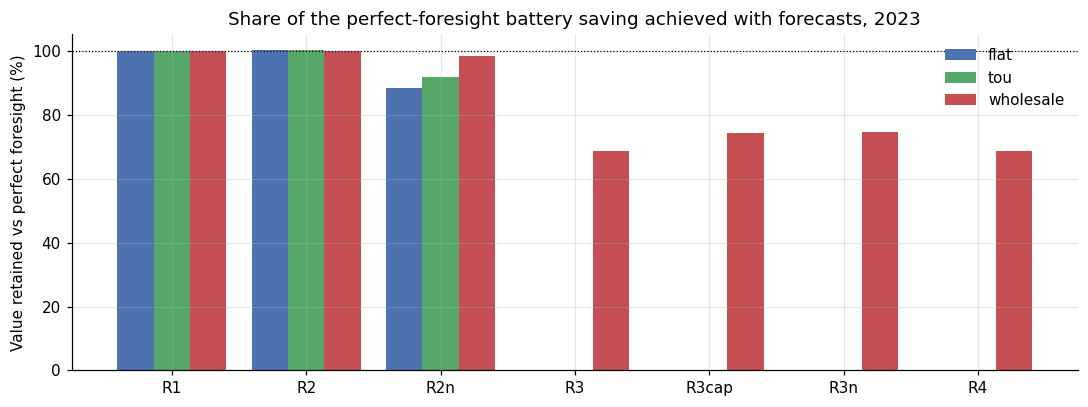

tariff   flat    tou  wholesale
run                            
R1      100.0  100.0      100.0
R2      100.4  100.4      100.1
R2n      88.6   91.9       98.5
R3        NaN    NaN       68.7
R3cap     NaN    NaN       74.3
R3n       NaN    NaN       74.7
R4        NaN    NaN       68.8


In [6]:
# Cell 5 - value retained figure
v = res[res.run != 'S1'].pivot(index='run', columns='tariff', values='value_retained').reindex(ORDER[1:])
fig, ax = plt.subplots(figsize=(10, 3.8))
xx = np.arange(len(v)); w_ = 0.27
for k_, (tname, c) in enumerate(zip(TARIFFS, ['#4c72b0', '#55a868', '#c44e52'])):
    ax.bar(xx + (k_ - 1) * w_, 100 * v[tname], w_, color=c, label=tname)
ax.axhline(100, color='k', lw=0.8, ls=':')
ax.set_xticks(xx); ax.set_xticklabels(v.index); ax.set_ylabel('Value retained vs perfect foresight (%)')
ax.set_title('Share of the perfect-foresight battery saving achieved with forecasts, 2023'); ax.legend(frameon=False)
plt.tight_layout(); fig.savefig(os.path.join(FIG_DIR, 'fig10a_value_retained.png'), dpi=200, bbox_inches='tight'); plt.show()
print((100 * v).round(1))

## Cell 6 — Where does the pre-dispatch run lose value? (wholesale)
Daily cost difference R3 − R1. If the losses sit on a few days, they are driven by price spikes (real or phantom), not by everyday error.
Also split the loss by whether the day had a real spike (actual 5-min spot > $300/MWh) and whether pre-dispatch (hour 1–24 ahead, issued
at 00:00) forecast one.

In [7]:
# Cell 6 - loss analysis
daily = pd.DataFrame({r: runs[('wholesale', r)].cost_aud.resample('D').sum() for r in ['R1', 'R3', 'R3cap', 'R3n', 'R4']})
loss = (daily[['R3', 'R3cap', 'R3n', 'R4']].sub(daily['R1'], axis=0))
top = loss['R3'].sort_values(ascending=False)
print('R3 annual loss vs R1: $%.0f | top 10 days: $%.0f (%.0f %%) | days with a loss > $1: %d'
      % (top.sum(), top.head(10).sum(), 100 * top.head(10).sum() / top.sum(), (top > 1).sum()))

real_spike = (y23.spot_aud_kwh > 0.300).resample('D').max().astype(bool)
pd_midnight = pd_wide[pd_wide.index.hour == 0][PD_COLS[:24]].max(axis=1)
fc_spike = (pd_midnight > 0.300).reindex(daily.index.normalize()).fillna(False).to_numpy()
cls = np.select([real_spike.to_numpy() & fc_spike, real_spike.to_numpy() & ~fc_spike, ~real_spike.to_numpy() & fc_spike],
                ['spike forecast and happened', 'spike missed', 'phantom spike (forecast only)'], 'no spike')
split = loss.groupby(cls).agg(['sum', 'count'])
print('\nLoss vs R1 by day type ($, number of days):'); print(split.round(0))

# hoarding check: average state of charge at the end of the evening peak (label 22:00) and at dawn (06:00)
soc_hours = pd.DataFrame({r: [runs[('wholesale', r)].soc_kwh.at_time(h).mean() for h in ['22:00', '06:00']]
                          for r in ['R1', 'R3', 'R3cap', 'R3n', 'R4']}, index=['mean SoC 22:00 (kWh)', 'mean SoC 06:00 (kWh)'])
print('\nHoarding check (wholesale):'); print(soc_hours.round(2))
print('\nTop 5 loss days (R3):')
print(pd.DataFrame({'R3 loss $': top.head(5).round(1), 'max actual spot $/MWh': (y23.spot_aud_kwh.resample('D').max() * 1000).reindex(top.head(5).index).round(0),
                    'max PD (00:00 issue) $/MWh': (pd_midnight * 1000).reindex(top.head(5).index).round(0)}))

R3 annual loss vs R1: $463 | top 10 days: $145 (31 %) | days with a loss > $1: 133

Loss vs R1 by day type ($, number of days):
                                  R3        R3cap          R3n           R4      
                                 sum count    sum count    sum count    sum count
no spike                        36.0   110   34.0   110   19.0   110   35.0   110
phantom spike (forecast only)   22.0    42   21.0    42   15.0    42   22.0    42
spike forecast and happened    323.0   149  243.0   149  250.0   149  322.0   149
spike missed                    83.0    64   83.0    64   91.0    64   82.0    64

Hoarding check (wholesale):
                        R1    R3  R3cap   R3n    R4
mean SoC 22:00 (kWh)  4.71  6.53   6.09  4.66  6.57
mean SoC 06:00 (kWh)  3.23  5.45   4.89  3.44  5.48

Top 5 loss days (R3):
            R3 loss $  max actual spot $/MWh  max PD (00:00 issue) $/MWh
datetime                                                                
2023-05-30       30.1     

## Cell 7 — Example: the worst R3 day and its neighbours
SoC under perfect foresight (R1), pre-dispatch (R3) and capped pre-dispatch (R3cap), with the actual spot price.
**Look for:** does R3 empty the battery in the real evening peak, or keep energy back for a forecast spike later?

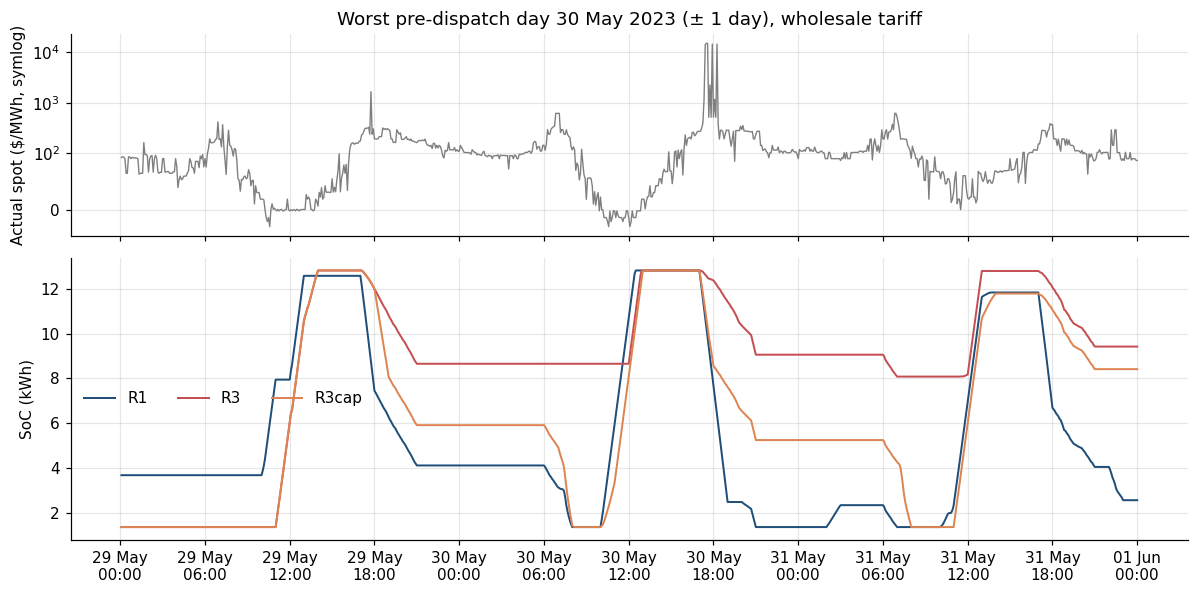

In [8]:
# Cell 7 - example days
d0 = top.index[0]
a, b = d0 - pd.Timedelta(days=1) + pd.Timedelta(minutes=5), d0 + pd.Timedelta(days=2)
fig, ax = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True, gridspec_kw={'height_ratios': [1, 1.4]})
ax[0].plot(y23.loc[a:b].index, y23.loc[a:b].spot_aud_kwh * 1000, color=COL['price'], lw=0.9)
ax[0].set_yscale('symlog', linthresh=100); ax[0].set_ylabel('Actual spot ($/MWh, symlog)')
ax[0].set_title(f'Worst pre-dispatch day {d0:%d %b %Y} (± 1 day), wholesale tariff')
for r in ['R1', 'R3', 'R3cap']:
    s = runs[('wholesale', r)].loc[a:b]
    ax[1].plot(s.index, s.soc_kwh, color=COL[r], lw=1.3, label=r)
ax[1].set_ylabel('SoC (kWh)'); ax[1].legend(frameon=False, ncol=3)
ax[1].xaxis.set_major_locator(mdates.HourLocator(byhour=[0, 6, 12, 18]))
ax[1].xaxis.set_major_formatter(mdates.DateFormatter('%d %b\n%H:%M'))
plt.tight_layout(); fig.savefig(os.path.join(FIG_DIR, 'fig10b_worst_day_R3.png'), dpi=200, bbox_inches='tight'); plt.show()

## Cell 8 — Cumulative loss over the year (wholesale)

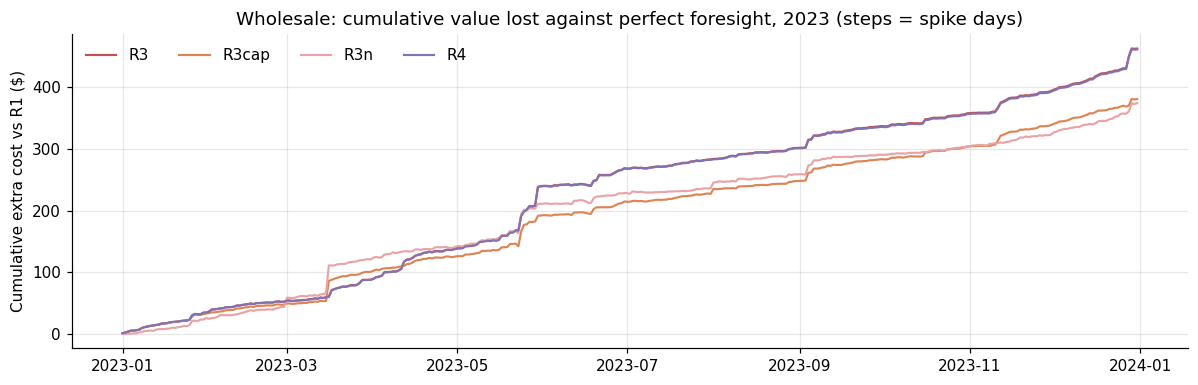

In [9]:
# Cell 8 - cumulative loss
fig, ax = plt.subplots(figsize=(11, 3.6))
for r in ['R3', 'R3cap', 'R3n', 'R4']:
    ax.plot(loss.index, loss[r].cumsum(), color=COL[r], lw=1.4, label=r)
ax.set_ylabel('Cumulative extra cost vs R1 ($)'); ax.legend(frameon=False, ncol=4)
ax.set_title('Wholesale: cumulative value lost against perfect foresight, 2023 (steps = spike days)')
plt.tight_layout(); fig.savefig(os.path.join(FIG_DIR, 'fig10c_cumulative_loss.png'), dpi=200, bbox_inches='tight'); plt.show()

## Cell 9 — Save

In [10]:
# Cell 9 - save
res.to_csv(os.path.join(OUT_DIR, 'nb07_results_2023.csv'), index=False)
loss.to_csv(os.path.join(OUT_DIR, 'nb07_daily_loss_wholesale.csv'))
for (tname, rname), r in runs.items():
    if rname not in ('S1', 'R1'):
        r.round(5).to_csv(os.path.join(OUT_DIR, f'nb07_dispatch_{tname}_{rname}.csv.gz'))
print('saved nb07_results_2023.csv, nb07_daily_loss_wholesale.csv and dispatch files')

saved nb07_results_2023.csv, nb07_daily_loss_wholesale.csv and dispatch files


## AI-use record (Appendix A)
| Item | Entry |
|---|---|
| Tool & model | Claude Opus 5.5 (Anthropic), claude.ai |
| What AI did | Wrote this notebook from my notes (runs R1–R4) and suggested the comparison runs R2n, R3n, R3cap |
| Example prompt | “notebook 6 done. now proceed with drafting notebook 7” |
| How I checked it | forecast sanity table in Cell 2; R1 equals Notebook 6 S3; looked at the worst-day plot |